# Memory experiment — decoder comparison

Memory experiment of a directional tile code with directional syndrome extraction, decoded with BP+LSD, BP+OSD, Relay-BP and Tesseract. Compares the logical error rate per round per logical qubit and the decoding time.

In [7]:
%pip install qldpc matplotlib sinter scipy tesseract-decoder "relay-bp[stim]"

Note: you may need to restart the kernel to use updated packages.


In [8]:
import csv
import os
import sys
from collections.abc import Mapping, Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sinter
from matplotlib.figure import Figure
from scipy.stats import beta as beta_distribution

import directional_tile_codes as dtc
from qldpc import circuits, codes, decoders
from qldpc.objects import PauliXZLike
from relay_bp.stim import sinter_decoders as make_relay_sinter_decoders
from tesseract_decoder import make_tesseract_sinter_decoders_dict

In [9]:
def make_decoder_registry() -> dict[str, sinter.Decoder]:
    relay = make_relay_sinter_decoders(
            gamma0=0.1,
            pre_iter=80,
            num_sets=60,
            set_max_iter=60,
            gamma_dist_interval=(-0.24, 0.66),
            stop_nconv=1,
        )
    tesseract = make_tesseract_sinter_decoders_dict()
    
    registry = {
        "bp_lsd": decoders.SinterDecoder(
            decoder=decoders.bp_lsd(
                max_iter=30, bp_method="ms", lsd_method="LSD_CS", lsd_order=0,
            )
        ),
        "bp_osd": decoders.SinterDecoder(
            decoder=decoders.bp_osd(
                max_iter=30, bp_method="ms", osd_method="OSD_CS", osd_order=0,
            )
        ),
        "relay_bp": relay["relay-bp"],
        "tesseract": tesseract["tesseract-short-beam"]
    }
    return registry

In [10]:
ERROR_RATES = tuple(np.logspace(-3, -2, 3))
ERROR_RATES_TESSERACT = tuple(np.logspace(-3, -2.5, 2))
print("Physical error rates (both bases):", ERROR_RATES)

NUM_WORKERS = max(1, min(4, (os.cpu_count() or 1) - 1))

experiment_1 = (100, 40_000, 20_000)
experiment_2 = (100, 60_000, 30_000)
experiment_3 = (200, 60_000, 30_000)
experiment_4 = (300, 60_000, 30_000)

MAX_ERRORS, BP_MAX_SHOTS, TESSERACT_MAX_SHOTS = experiment_3

CUSTOM_DECODERS = make_decoder_registry()
BP_DECODERS = {key: CUSTOM_DECODERS[key] for key in ("bp_lsd", "bp_osd", "relay_bp")}
TESSERACT_DECODERS = {"tesseract": CUSTOM_DECODERS["tesseract"]}

word_name = "NESEN"
dtc_codes = [
    (dtc.DirectionalTileCode(M=22, N=3, word=dtc.DirectionalWord(word_name)), 4)
]

RESULTS_ROOT = Path(".") if Path.cwd().name == "results" else Path("results")
if not RESULTS_ROOT.is_dir():
    raise FileNotFoundError(
        f"Cannot find the results directory from {Path.cwd()}. "
        "Start Jupyter from the repository root or results/."
    )
RESULTS_DIR = (RESULTS_ROOT / "dtc_comparison_decoders_results" / word_name
               / f"experiment_{MAX_ERRORS}_{BP_MAX_SHOTS // 1000}_{TESSERACT_MAX_SHOTS // 1000}")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Results directory:", RESULTS_DIR.resolve())
print("BP decoders:", list(BP_DECODERS))
print("Separate Tesseract:", list(TESSERACT_DECODERS))

Physical error rates (both bases): (np.float64(0.001), np.float64(0.0031622776601683794), np.float64(0.01))
Results directory: /Users/frafino/Desktop/directional_codes/results/dtc_comparison_decoders_results/NESEN/experiment_200_60_30
BP decoders: ['bp_lsd', 'bp_osd', 'relay_bp']
Separate Tesseract: ['tesseract']


## 3. Build only custom directional-memory Sinter tasks

In [11]:
def code_label(code: codes.CSSCode) -> str:
    known_distance = code.get_distance_if_known()
    suffix = f", {known_distance}" if known_distance is not None else ""
    return f"[[{len(code)}, {code.dimension}{suffix}]]"


def build_memory_tasks(
    codes_and_rounds: Sequence[tuple[dtc.DirectionalTileCode, int]],
    basis: PauliXZLike,
    *,
    error_rates: Sequence[float] = ERROR_RATES,
) -> list[sinter.Task]:
    """Build ONLY the custom directional extraction memory circuits."""
    for _, num_rounds in codes_and_rounds:
        if (
            isinstance(num_rounds, (bool, np.bool_))
            or not isinstance(num_rounds, (int, np.integer))
            or num_rounds < 2
            or num_rounds % 2
        ):
            raise ValueError("Each round count must be a positive even integer >= 2.")

    tasks = []
    for tile_code, num_rounds in codes_and_rounds:
        num_rounds = int(num_rounds)
        code = tile_code.css_code
        strategy = dtc.DirectionalSyndromeMeasurement(tile_code)
        word = "".join(direction.name for direction in tile_code.word.word)

        num_calls = num_rounds // 2
        for probability in error_rates:
            noise = circuits.DepolarizingNoiseModel(
                float(probability),
                include_idling_error=False,
            )
            circuit = circuits.get_memory_experiment(
                code,
                basis=basis,
                num_rounds=num_calls,
                noise_model=noise,
                qubit_ids = strategy.get_qubit_ids(),
                syndrome_measurement_strategy = strategy,
            )
            dem = circuit.detector_error_model()
            num_logicals = int(circuit.num_observables)
            if num_logicals != int(code.dimension):
                raise ValueError(
                    f"{word}, {basis}, directional: circuit tracks "
                    f"{num_logicals} observables, but code has k={code.dimension}. "
                    "Inspect the tracked logical observables before using per-logical-qubit normalization."
                )
            if num_logicals < 1:
                raise ValueError("The circuit tracks no logical observables.")
            tasks.append(
                sinter.Task(
                    circuit=circuit,
                    detector_error_model=dem,
                    json_metadata={
                        "label": code_label(code),
                        "word": word,
                        "basis": str(basis),
                        "strategy": "directional",
                        "probability": float(probability),
                        "num_rounds": num_rounds,
                        "extraction_calls": num_calls,
                        "num_logicals": num_logicals,
                    },
                )
            )
    return tasks


def run_memory_experiments(
    codes_and_rounds: Sequence[tuple[dtc.DirectionalTileCode, int]],
    basis: PauliXZLike,
    *,
    custom_decoders: Mapping[str, sinter.Decoder] = CUSTOM_DECODERS,
    error_rates: Sequence[float] = ERROR_RATES,
    max_shots: int = BP_MAX_SHOTS,
    max_errors: int = MAX_ERRORS,
    save_resume_filepath: str | None = None,
) -> list[sinter.TaskStats]:
    tasks = build_memory_tasks(codes_and_rounds, basis, error_rates=error_rates)
    if not tasks:
        return []
    options = dict(
        tasks=tasks,
        decoders=list(custom_decoders),
        custom_decoders=dict(custom_decoders),
        num_workers=NUM_WORKERS,
        max_shots=max_shots,
        max_errors=max_errors,
        print_progress=True,
    )
    if save_resume_filepath is not None:
        options["save_resume_filepath"] = save_resume_filepath
    return sinter.collect(**options)

## 4. Effective error rates, confidence intervals, and comparison plots
The shot failure rate is converted to a logical error rate per round per logical qubit, $p_L = 1-(1-p_{shot})^{1/(kR)}$, with 95% Jeffreys intervals.

In [12]:
def effective_rate(p_shot: float, per_k_per_round: int) -> float:
    if per_k_per_round <= 0 or not 0 <= p_shot <= 1:
        raise ValueError("Expected positive k*R and shot failure probability in [0, 1].")
    return float(-np.expm1(np.log1p(-p_shot) / per_k_per_round))


def rate_summary(stat: sinter.TaskStats, credible_mass: float = 0.95) -> dict:
    n = int(stat.shots - stat.discards)
    e = int(stat.errors)
    if n <= 0:
        raise ValueError("Cannot estimate a rate without non-discarded shots.")
    if not 0 <= e <= n:
        raise ValueError(f"Invalid failure count {e} for {n} accepted shots.")
    k = int(stat.json_metadata["num_logicals"])
    rounds = int(stat.json_metadata["num_rounds"])
    per_k_per_round = k * rounds
    alpha = (1 - credible_mass) / 2
    lower = beta_distribution.ppf(alpha, e + 0.5, n - e + 0.5)
    upper = beta_distribution.ppf(1 - alpha, e + 0.5, n - e + 0.5)
    return {
        "probability": float(stat.json_metadata["probability"]),
        "decoder": stat.decoder,
        "basis": str(stat.json_metadata["basis"]),
        "strategy": stat.json_metadata["strategy"],
        "word": stat.json_metadata["word"],
        "rounds": rounds,
        "num_logicals": k,
        "shots": int(stat.shots),
        "discards": int(stat.discards),
        "errors": e,
        "p_shot": e / n,
        "p_effective": effective_rate(e / n, per_k_per_round),
        "lower_95": effective_rate(lower, per_k_per_round),
        "upper_95": effective_rate(upper, per_k_per_round),
    }


def plot_decoder_comparison(
    stats: Sequence[sinter.TaskStats],
    *,
    title: str,
) -> tuple[Figure, np.ndarray]:
    figure, axes = plt.subplots(1, 2, figsize=(13, 5.3), sharex=True, sharey=True)
    markers = {"bp_lsd": "o", "bp_osd": "s", "relay_bp": "^", "tesseract": "D"}
    colors = dict(zip(sorted({s.decoder for s in stats}), plt.get_cmap("tab10").colors))
    summaries = [rate_summary(s) for s in stats]
    for i, basis in enumerate(("X", "Z")):
        ax = axes[i]
        group = [r for r in summaries if r["basis"].upper().endswith(basis)]
        for decoder in sorted({r["decoder"] for r in group}):
            points = sorted((r for r in group if r["decoder"] == decoder), key=lambda r: r["probability"])
            observed = [r for r in points if r["errors"] > 0]
            if observed:
                xs = np.array([r["probability"] for r in observed])
                ys = np.array([r["p_effective"] for r in observed])
                err_low = np.array([max(r["p_effective"] - r["lower_95"], 0) for r in observed])
                err_high = np.array([max(r["upper_95"] - r["p_effective"], 0) for r in observed])
                ax.errorbar(
                    xs, ys, yerr=np.array([err_low, err_high]),
                    color=colors[decoder], marker=markers.get(decoder, "o"),
                    linestyle="-", capsize=2, linewidth=1.4, markersize=5,
                    label=decoder,
                )
            bounds = [r for r in points if r["errors"] == 0]
            offsets = {
                "bp_lsd": 0.98,
                "bp_osd": 0.99,
                "relay_bp": 1.01,
                "tesseract": 1.02,
            }

            if bounds:
                ax.scatter(
                    [r["probability"] * offsets[decoder] for r in bounds],
                    [r["upper_95"] for r in bounds],
                    color=colors[decoder],
                    marker="v",
                    s=65,
                    edgecolors="black",
                    linewidths=0.4,
                    label=f"{decoder} (0 failures; upper bound)",
                    zorder=5,
                )
        ax.set(xscale="log", yscale="log", title=f"{basis}-basis")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend(loc="best", fontsize=8)
        ax.set_xlabel("physical depolarizing probability p")
    axes[0].set_ylabel("effective logical error per round per logical qubit")
    figure.suptitle(title, fontsize=14)
    figure.tight_layout()
    return figure, axes


def write_sinter_csv(path: str, stats: Sequence[sinter.TaskStats]) -> None:
    with open(path, "w", encoding="utf-8") as f:
        print(sinter.CSV_HEADER, file=f)
        for s in stats:
            print(s.to_csv_line(), file=f)


def write_normalized_csv(path: str, stats: Sequence[sinter.TaskStats]) -> None:
    rows = [rate_summary(s) for s in stats]
    if not rows:
        return
    with open(path, "w", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

In [13]:
def checkpoint_path(basis: str, group: str) -> Path:
    return RESULTS_DIR / f"{basis}_{group}_resume.csv"

print("Expected benchmarks per basis:", len(ERROR_RATES) * len(CUSTOM_DECODERS))
print("X/Z rates:", ERROR_RATES)

Expected benchmarks per basis: 12
X/Z rates: (np.float64(0.001), np.float64(0.0031622776601683794), np.float64(0.01))


## A. BP+LSD, BP+OSD, Relay-BP

In [14]:
bp_stats = []
for basis in ("X", "Z"):
    bp_stats.extend(
        run_memory_experiments(
            dtc_codes,
            basis,
            custom_decoders=BP_DECODERS,
            error_rates=ERROR_RATES,
            max_shots=BP_MAX_SHOTS,
            max_errors=MAX_ERRORS,
            save_resume_filepath=str(checkpoint_path(basis, "bp")),
        )
    )
print("BP-family task-decoder results:", len(bp_stats))

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
Starting 4 workers...
9 tasks left:
  workers  decoder eta shots_left errors_left json_metadata                                                                                                                            
        1   bp_lsd   ?      60000         200 label=[[165, 2]],word=NESEN,basis=X,strategy=directional,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        1   bp_osd   ?      60000         200 label=[[165, 2]],word=NESEN,basis=X,strategy=directional,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        1 relay_bp 10m      59983         200 label=[[165, 2]],word=NESEN,basis=X,strategy=directional,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        1   bp_lsd   ?      60000         200 label=[[165, 2]],word=NESEN,basis=X,strategy=directional,probability=0.00316227766016

BP-family task-decoder results: 36


## B. Tesseract — independent run
Tesseract is much slower, so it runs separately with fewer shots and error rates.

In [15]:
tesseract_stats = []
for basis in ("X", "Z"):
    tesseract_stats.extend(
        run_memory_experiments(
            dtc_codes,
            basis,
            custom_decoders=TESSERACT_DECODERS,
            error_rates=ERROR_RATES_TESSERACT,
            max_shots=TESSERACT_MAX_SHOTS,
            max_errors=MAX_ERRORS,
            save_resume_filepath=str(checkpoint_path(basis, "tesseract")),
        )
    )
print("Tesseract task-decoder results:", len(tesseract_stats))

Starting 4 workers...
2 tasks left:
  workers   decoder eta shots_left errors_left json_metadata                                                                                                                            
        2 tesseract  3m      29999         200 label=[[165, 2]],word=NESEN,basis=X,strategy=directional,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        2 tesseract   ?      30000         200 label=[[165, 2]],word=NESEN,basis=X,strategy=directional,probability=0.0031622776601683794,num_rounds=4,extraction_calls=2,num_logicals=2
2 tasks left:
  workers   decoder eta shots_left errors_left json_metadata                                                                                                                            
        2 tesseract  6m      29998         200 label=[[165, 2]],word=NESEN,basis=X,strategy=directional,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        2 tesseract 17m  

Tesseract task-decoder results: 8


## C. Replot
Reload the checkpoints, plot the comparison and export the CSVs.

Read 44 task-decoder results from:
   dtc_comparison_decoders_results/NESEN/experiment_200_60_30/X_bp_resume.csv
   dtc_comparison_decoders_results/NESEN/experiment_200_60_30/X_tesseract_resume.csv
   dtc_comparison_decoders_results/NESEN/experiment_200_60_30/Z_bp_resume.csv
   dtc_comparison_decoders_results/NESEN/experiment_200_60_30/Z_tesseract_resume.csv


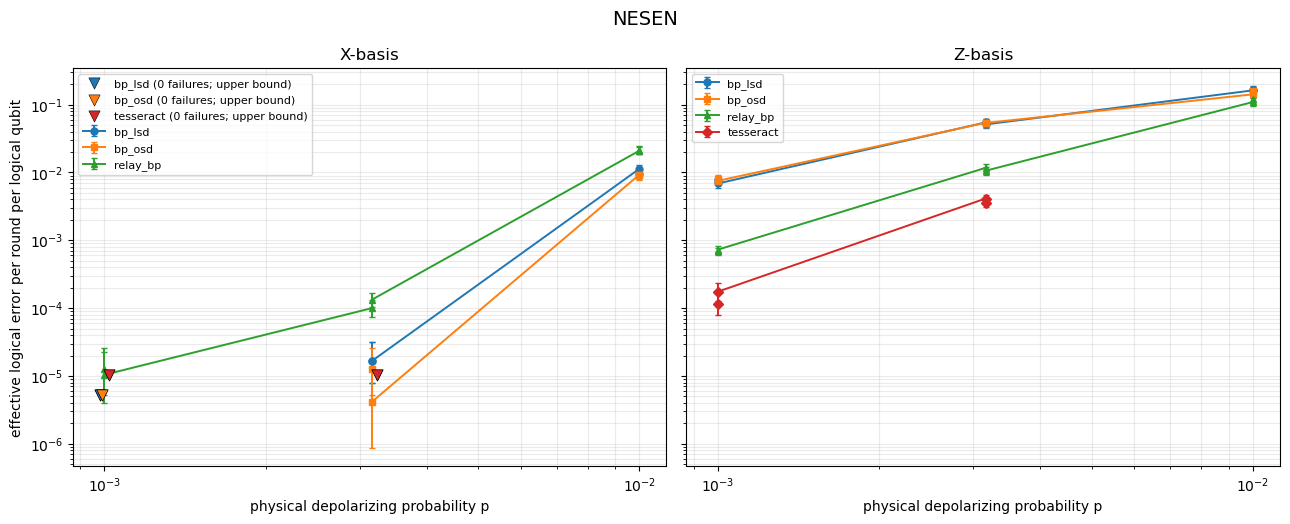

In [16]:
checkpoint_files = [
    checkpoint_path(basis, group)
    for basis in ("X", "Z")
    for group in ("bp", "tesseract")
    if checkpoint_path(basis, group).is_file()
    and checkpoint_path(basis, group).stat().st_size > 0
]
if not checkpoint_files:
    raise FileNotFoundError(
        f"No new checkpoints in {RESULTS_DIR}. "
        "Run block A and/or B first, or load your earlier CSV separately."
    )

# Each checkpoint is loaded ONCE. Never include an aggregate/export of these files here.
all_stats = sinter.read_stats_from_csv_files(*checkpoint_files)
if not all_stats:
    raise ValueError("Checkpoint files exist but contain no completed shots yet.")
print("Read", len(all_stats), "task-decoder results from:")
for path in checkpoint_files:
    print("  ", path)

fig, axes = plot_decoder_comparison(all_stats, title=word_name)
fig.savefig(
    RESULTS_DIR / "decoder_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

write_sinter_csv(str(RESULTS_DIR / "separate_stats.csv"), all_stats)
write_normalized_csv(str(RESULTS_DIR / "separate_effective_rates.csv"), all_stats)

## D. Decoding time
Sinter stores the CPU time (`seconds`, summed over workers) spent sampling and decoding each task. Sampling is the same for every decoder, so time per shot compares decoder cost.

Experiments: ['experiment_100_40_20', 'experiment_100_60_30', 'experiment_200_60_30', 'experiment_300_60_30']

ms per shot, experiment_200_60_30:


decoder            bp_lsd  bp_osd  relay_bp  tesseract
basis probability                                     
X     0.001000       10.1    10.4      11.2       16.7
      0.003162       24.8    17.1      47.2      277.2
      0.010000      204.7    24.3     680.8        NaN
Z     0.001000       12.1    12.1      17.8       23.1
      0.003162       26.7    18.7      74.4      599.3
      0.010000      170.5    20.8     897.4        NaN

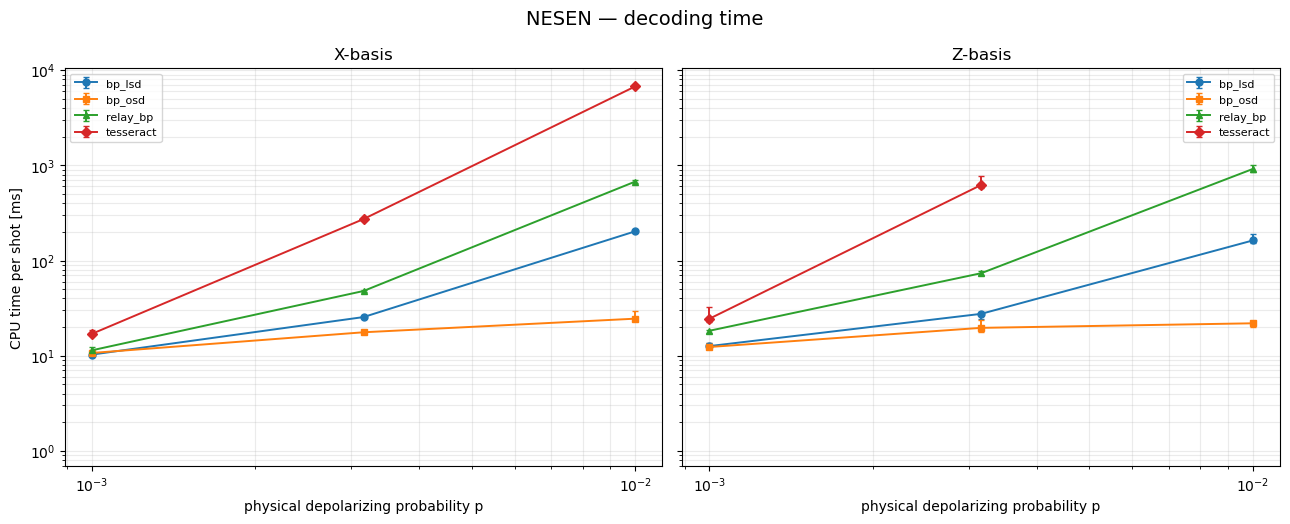

In [17]:
import pandas as pd


def timing_table(word_dir: Path) -> pd.DataFrame:
    rows = []
    for path in sorted(word_dir.glob("experiment_*/separate_stats.csv")):
        for s in sinter.read_stats_from_csv_files(path):
            rows.append({
                "experiment": path.parent.name,
                "basis": s.json_metadata["basis"],
                "decoder": s.decoder,
                "probability": round(float(s.json_metadata["probability"]), 6),
                "shots": s.shots,
                "seconds": s.seconds,
                "ms_per_shot": 1000 * s.seconds / s.shots,
            })
    return pd.DataFrame(rows)


def plot_decoding_time(timing: pd.DataFrame, *, title: str) -> tuple[Figure, np.ndarray]:
    figure, axes = plt.subplots(1, 2, figsize=(13, 5.3), sharex=True, sharey=True)
    markers = {"bp_lsd": "o", "bp_osd": "s", "relay_bp": "^", "tesseract": "D"}
    colors = dict(zip(sorted(timing["decoder"].unique()), plt.get_cmap("tab10").colors))
    summary = (timing.groupby(["basis", "decoder", "probability"])["ms_per_shot"]
               .agg(["median", "min", "max"]).reset_index())
    for ax, basis in zip(axes, ("X", "Z")):
        for decoder, group in summary[summary["basis"] == basis].groupby("decoder"):
            ax.errorbar(
                group["probability"], group["median"],
                yerr=[group["median"] - group["min"], group["max"] - group["median"]],
                color=colors[decoder], marker=markers.get(decoder, "o"),
                capsize=2, linewidth=1.4, markersize=5, label=decoder,
            )
        ax.set(xscale="log", yscale="log", title=f"{basis}-basis")
        ax.set_xlabel("physical depolarizing probability p")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend(loc="best", fontsize=8)
    axes[0].set_ylabel("CPU time per shot [ms]")
    figure.suptitle(title, fontsize=14)
    figure.tight_layout()
    return figure, axes


timing = timing_table(RESULTS_DIR.parent)
print("Experiments:", sorted(timing["experiment"].unique()))

print(f"\nms per shot, {RESULTS_DIR.name}:")
display(timing[timing["experiment"] == RESULTS_DIR.name]
        .pivot_table(index=["basis", "probability"], columns="decoder", values="ms_per_shot")
        .round(1))

fig, axes = plot_decoding_time(timing, title=f"{word_name} — decoding time")
fig.savefig(RESULTS_DIR.parent / "decoding_time.png", dpi=200, bbox_inches="tight")
plt.show()